In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("train.csv")

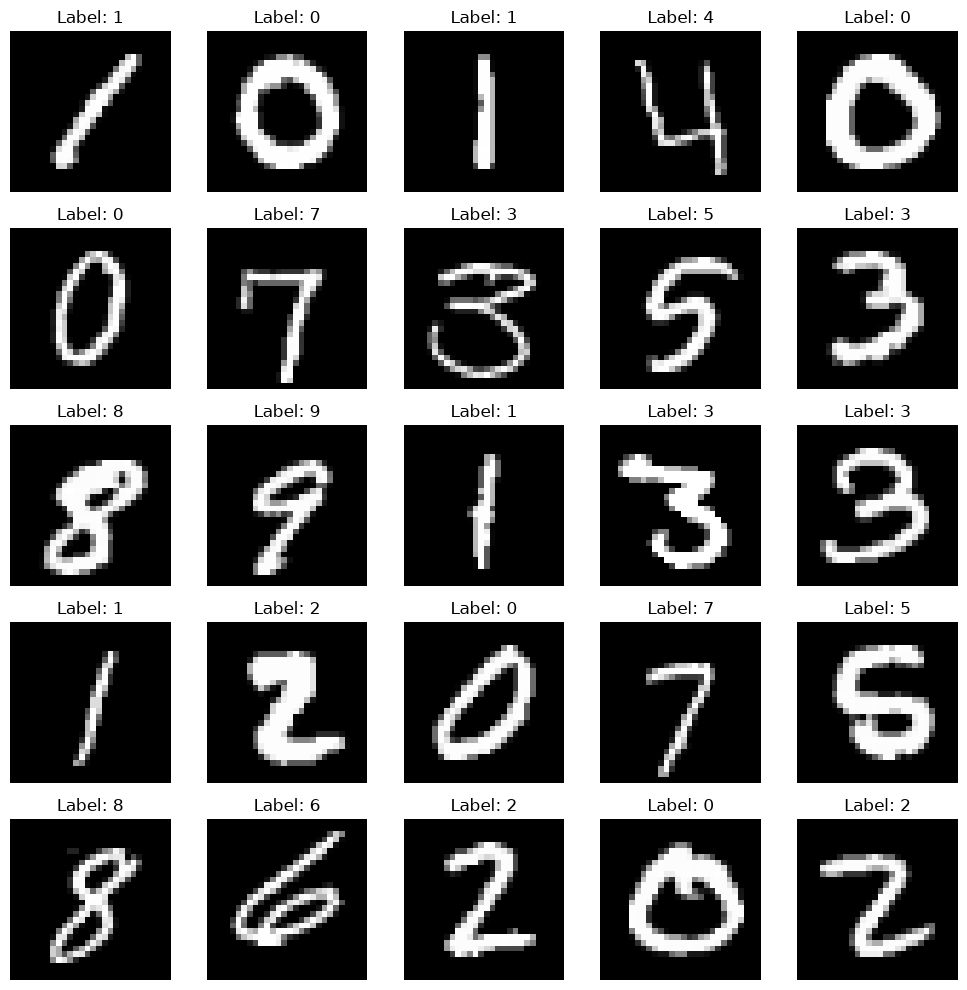

In [ ]:
fig, axes = plt.subplots(5, 5, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    pixels = df.iloc[i].drop("label").to_numpy()

    image = pixels.reshape(28, 28)

    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Label: {df.iloc[i]['label']}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# EDA
공통 준비: train/test를 `(N, 28, 28)` 배열로 만든다.

In [ ]:
import numpy as np

test_df = pd.read_csv("test.csv")
y = df["label"].to_numpy()
X = df.drop(columns="label").to_numpy().reshape(-1, 28, 28)
X_test = test_df.to_numpy().reshape(-1, 28, 28)
X.shape, X_test.shape

## 1. 데이터 개수
Train/Test 샘플 수와 결측치.

In [ ]:
print(f"Train: {len(df):,}  ({df.shape[1]} cols = label + {df.shape[1]-1} pixels)")
print(f"Test : {len(test_df):,}  ({test_df.shape[1]} cols)")
print("결측치 train/test:", df.isna().sum().sum(), test_df.isna().sum().sum())

## 2. 클래스 분포
불균형이 크면 가중치·샘플링이 필요하다.

In [ ]:
counts = df["label"].value_counts().sort_index()
ratio = counts / counts.sum() * 100

plt.figure(figsize=(8, 3))
plt.bar(counts.index, counts.values)
for k, v in counts.items():
    plt.text(k, v, f"{ratio[k]:.1f}%", ha="center", va="bottom", fontsize=8)
plt.xticks(range(10)); plt.title("Train class distribution"); plt.show()
print(f"max/min 비율: {counts.max() / counts.min():.2f}")

## 3. 이미지 크기 / 4. 종횡비 / 5. 채널
CSV는 784(=28×28×1) 픽셀이라 캔버스 크기·채널은 모두 동일하다. 대신 **숫자가 실제로 차지하는 영역(bounding box)** 의 크기와 종횡비를 본다.

In [ ]:
assert df.shape[1] - 1 == 28 * 28 == test_df.shape[1]
print("캔버스: 28x28, 채널: 1 (Grayscale), 값 범위:", X.min(), "~", X.max())

def bbox_stats(imgs):
    ink = imgs > 0
    rows, cols = ink.any(2), ink.any(1)
    h = 28 - rows.argmax(1) - rows[:, ::-1].argmax(1)
    w = 28 - cols.argmax(1) - cols[:, ::-1].argmax(1)
    return w, h

w, h = bbox_stats(X)
w_t, h_t = bbox_stats(X_test)
print("빈 이미지 수 train/test:", (X.reshape(len(X), -1).max(1) == 0).sum(), (X_test.reshape(len(X_test), -1).max(1) == 0).sum())

fig, axes = plt.subplots(1, 3, figsize=(14, 3))
axes[0].hist(w, bins=range(30)); axes[0].set_title("Bbox width")
axes[1].hist(h, bins=range(30)); axes[1].set_title("Bbox height")
aspect = w / h
axes[2].hist(aspect, bins=50); axes[2].set_title("Aspect ratio (w/h)")
plt.show()

pd.DataFrame({"label": y, "w": w, "h": h, "aspect": aspect}).groupby("label").mean().round(2)

## 6. 픽셀 분포
정규화 상수(mean/std)와 픽셀값 히스토그램. 대부분이 0(배경)이다.

In [ ]:
px = X / 255.0
print(f"mean={px.mean():.4f}, std={px.std():.4f}  (train.ipynb 의 Normalize 0.1307/0.3081 과 비교)")
print(f"0인 픽셀 비율: {(X == 0).mean() * 100:.1f}%, 255인 픽셀 비율: {(X == 255).mean() * 100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
axes[0].hist(X.ravel(), bins=256, log=True); axes[0].set_title("Pixel histogram (log)")
axes[1].hist(X[X > 0].ravel(), bins=255); axes[1].set_title("Pixel histogram (non-zero)")
plt.show()

## 7. 밝기·대비
이미지별 평균 밝기(≈잉크 양)와 표준편차(대비). 클래스별로 차이가 크면 augmentation 범위 설정에 참고.

In [ ]:
flat = X.reshape(len(X), -1)
img_df = pd.DataFrame({"label": y, "brightness": flat.mean(1), "contrast": flat.std(1),
                       "ink_ratio": (flat > 0).mean(1)})

fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, col in zip(axes, ["brightness", "contrast", "ink_ratio"]):
    img_df.boxplot(column=col, by="label", ax=ax, grid=False)
    ax.set_title(col); ax.set_xlabel("")
plt.suptitle(""); plt.show()
img_df.groupby("label")[["brightness", "contrast", "ink_ratio"]].mean().round(3)

## 8. 이미지 시각화
클래스별 샘플 10개와 클래스 평균 이미지.

In [ ]:
fig, axes = plt.subplots(10, 11, figsize=(11, 10))
rng = np.random.default_rng(0)
for d in range(10):
    idx = rng.choice(np.where(y == d)[0], 10, replace=False)
    for j, i in enumerate(idx):
        axes[d, j].imshow(X[i], cmap="gray")
    axes[d, 10].imshow(X[y == d].mean(0), cmap="magma")
    axes[d, 0].set_ylabel(d, rotation=0, labelpad=10)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 10].set_title("mean", fontsize=9)
plt.tight_layout(); plt.show()

## 9. 중복 이미지
완전 중복은 바이트 해시로, 유사 중복은 14×14로 줄여 이진화한 해시로 찾는다.
(유사 판정은 거친 근사다. 더 정밀하게 하려면 임베딩 + 최근접 이웃 거리를 쓴다.)

In [ ]:
def exact_hash(imgs):
    return pd.Series([a.tobytes() for a in imgs.astype(np.uint8)])

def near_hash(imgs):
    small = imgs.reshape(-1, 14, 2, 14, 2).mean((2, 4)) > 64
    return pd.Series([a.tobytes() for a in small])

for name, fn in [("exact", exact_hash), ("near", near_hash)]:
    tr, te = fn(X), fn(X_test)
    print(f"[{name}] train 내부 중복: {tr.duplicated().sum()}, test 내부 중복: {te.duplicated().sum()}, "
          f"train∩test: {te.isin(set(tr)).sum()}")

# 유사 중복인데 라벨이 다른 쌍 (라벨 충돌)
nh = near_hash(X)
grp = pd.DataFrame({"h": nh, "label": y}).groupby("h")["label"].nunique()
conflict = grp[grp > 1].index
print("유사 중복이면서 라벨이 다른 그룹 수:", len(conflict))

## 10. 라벨 품질
라벨 범위·누락 확인 후, **자기 클래스 평균 이미지에서 가장 먼 샘플**을 오라벨/이상치 후보로 눈으로 확인한다. (평균 템플릿은 약한 분류기라 "다른 클래스에 더 가까움" 비율 자체는 오라벨 비율이 아니다.)

In [ ]:
print("라벨 값:", sorted(df["label"].unique()), "/ 누락:", df["label"].isna().sum())

means = np.stack([px[y == d].mean(0) for d in range(10)]).reshape(10, -1)
flat_px = px.reshape(len(px), -1)
dist = (flat_px ** 2).sum(1, keepdims=True) - 2 * flat_px @ means.T + (means ** 2).sum(1)   # (N, 10) 제곱거리
own = dist[np.arange(len(y)), y]
nearest = dist.argmin(1)
suspect = np.where(nearest != y)[0]
print(f"평균 템플릿 기준 다른 클래스에 더 가까운 샘플 (참고용): {len(suspect)} ({len(suspect) / len(y) * 100:.1f}%)")

# 자기 클래스 평균에서 가장 먼 16개
worst = np.argsort(own)[::-1][:16]
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, i in zip(axes.flat, worst):
    ax.imshow(X[i], cmap="gray"); ax.set_title(f"y={y[i]} near={nearest[i]}", fontsize=8); ax.axis("off")
plt.suptitle("Outlier candidates (farthest from own class mean)"); plt.tight_layout(); plt.show()

## 11. Train/Test 차이
밝기·잉크 양·bbox 분포와 평균 이미지를 비교해 domain shift를 확인한다.

In [ ]:
flat_t = X_test.reshape(len(X_test), -1)
stats = pd.DataFrame({
    "train": [px.mean(), px.std(), flat.mean(1).mean(), (flat > 0).mean(), w.mean(), h.mean()],
    "test":  [(X_test / 255).mean(), (X_test / 255).std(), flat_t.mean(1).mean(), (flat_t > 0).mean(), w_t.mean(), h_t.mean()],
}, index=["pixel mean", "pixel std", "brightness", "ink ratio", "bbox w", "bbox h"]).round(4)
display(stats)

fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, a, b, title in [(axes[0], flat.mean(1), flat_t.mean(1), "brightness"),
                        (axes[1], w, w_t, "bbox width"),
                        (axes[2], h, h_t, "bbox height")]:
    ax.hist(a, bins=40, density=True, alpha=.5, label="train")
    ax.hist(b, bins=40, density=True, alpha=.5, label="test")
    ax.set_title(title); ax.legend()
im = axes[3].imshow(X.mean(0) - X_test.mean(0), cmap="bwr", vmin=-10, vmax=10)
axes[3].set_title("mean(train) - mean(test)"); plt.colorbar(im, ax=axes[3])
plt.show()

## 12. 검증 데이터 구성
Kaggle Digit Recognizer에는 그룹·시간·촬영 환경 메타데이터가 없다. 따라서 **클래스 비율을 유지하는 stratified split**이 기본이다. `train.ipynb`의 `random_split`과 stratified split의 클래스 비율 차이를 비교한다.

In [ ]:
import torch
from torch.utils.data import random_split

rand_val = np.array(random_split(range(len(y)), [0.9, 0.1], generator=torch.Generator().manual_seed(42))[1].indices)

rng = np.random.default_rng(42)
strat_val = np.concatenate([rng.choice(np.where(y == d)[0], round((y == d).sum() * 0.1), replace=False) for d in range(10)])

base = np.bincount(y, minlength=10) / len(y)
cmp = pd.DataFrame({
    "full": base,
    "random_split val": np.bincount(y[rand_val], minlength=10) / len(rand_val),
    "stratified val": np.bincount(y[strat_val], minlength=10) / len(strat_val),
}).mul(100).round(2)
cmp["random 편차(%p)"] = (cmp["random_split val"] - cmp["full"]).round(2)
cmp

## 요약
| 항목 | 결과 | 결정 |
| --- | --- | --- |
| 데이터 개수 | Train 42,000 / Test 28,000, 결측치 0 | — |
| 클래스 분포 | 3,795(5) ~ 4,684(1), max/min 1.23 | 가중치·리샘플링 불필요 |
| 크기·종횡비 | 캔버스 28×28 고정, 숫자 bbox 평균 15.7×19.7 | Resize 불필요, 작은 scale/translate augmentation |
| 채널 | Grayscale 1채널 | `in_channels=1` |
| 픽셀 분포 | mean 0.1310 / std 0.3085, 80.8%가 0 | 기존 Normalize(0.1307, 0.3081) 그대로 사용 가능 |
| 밝기·대비 | 7번 클래스별 표 참고 | 기하 변환 위주, 좌우 반전 금지 |
| 중복 | 완전 중복 0, train∩test 0, 유사 중복 그룹 내 라벨 충돌 0 | 누수 없음 |
| 라벨 품질 | 라벨 0~9, 누락 0 | 이상치 후보는 10번 그림으로 확인 |
| Train/Test 차이 | 픽셀·밝기·bbox 통계 거의 동일 (bbox h 19.75 vs 19.74) | Domain shift 없음 |
| 검증 구성 | 메타데이터 없음, random_split 클래스 비율 편차 최대 0.8%p | stratified split 권장 (영향은 작음) |